# EDA bộ dữ liệu HDFS_v1

Mục tiêu: hiểu dữ liệu trước khi viết `split_data.py`, `dataset.py`, `detect.py`. Mỗi phần trả lời 1 câu hỏi
cần cho một quyết định thiết kế:

| Phần | Câu hỏi | Quyết định liên quan |
|---|---|---|
| 2 | Độ dài session phân bố thế nào? Bao nhiêu session ngắn hơn cửa sổ h? | xử lý session ngắn trong `dataset.py` / `detect.py` |
| 3 | Bất thường phân bố theo thời gian ra sao? | mốc cắt chronological, session Anomaly trước mốc cắt |
| 4 | Sự kiện nào chỉ có ở session bất thường? | giải thích vì sao HDFS "dễ", baseline luật đơn giản |
| 5 | Luật từ khoá (WARN) và luật cấu trúc đơn giản đạt bao nhiêu? | mốc so sánh dưới cùng cho DeepLog |
| 6 | Chuỗi trùng lặp nhiều không? | ý nghĩa của kết quả test |

**Nguồn dữ liệu.** Chuỗi sự kiện lấy từ `Event_traces.csv` của Loghub. `python -m src.validate_parsing` đã xác nhận
Drain3 (với `configs/drain3.ini` hiện tại) cho chuỗi trùng khít file này ở 575.061/575.061 block, nên kết luận ở đây
áp dụng được cho pipeline Drain3. Thời điểm bắt đầu của block lấy từ `data/interim/block_stats.csv`
(chạy `python -m src.block_stats` trước).

Chạy từ thư mục gốc project: `jupyter notebook notebooks/01_eda_hdfs.ipynb`.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.block_stats import load_block_stats
from src.config import load_config
from src.parse_logs import build_header_regex
from src.utils import ensure_dir
from src.validate_parsing import NO_MATCH, build_reference_matcher, load_reference_templates

cfg = load_config()
paths = cfg["paths"]
H = cfg["model"]["window_size"]
FIG_DIR = ensure_dir(ROOT / "outputs" / "figures")
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Tải dữ liệu

In [2]:
traces = pd.read_csv(paths["ref_traces"], usecols=["BlockId", "Label", "Type", "Features"])
traces["Seq"] = traces["Features"].str.strip("[]").str.split(",")
traces["Len"] = traces["Seq"].str.len()

stats = load_block_stats(paths["block_stats"])
df = traces.merge(stats, on="BlockId", how="inner")
df["y"] = (df["Label"] == "Fail").astype(int)   # 1 = Anomaly

ref_templates = load_reference_templates(paths["ref_templates"])
template_text = dict(zip(ref_templates["EventId"], ref_templates["EventTemplate"].str.replace("[*]", " * ").str.strip()))

assert len(df) == len(traces) == len(stats), "block_stats và Event_traces phải có cùng tập block"
print(f"Số session: {len(df):,}")
print(f"Normal: {(df.y == 0).sum():,}   Anomaly: {(df.y == 1).sum():,}   ({df.y.mean():.2%})")
print(f"Số dòng log (tổng độ dài chuỗi): {df.Len.sum():,}")
print(f"Thời gian: {df.StartTime.min()} → {df.EndTime.max()}  ({(df.EndTime.max() - df.StartTime.min()).total_seconds() / 3600:.1f} giờ)")

Số session: 575,061
Normal: 558,223   Anomaly: 16,838   (2.93%)
Số dòng log (tổng độ dài chuỗi): 11,175,629
Thời gian: 2008-11-09 20:35:18 → 2008-11-11 11:16:28  (38.7 giờ)


## 2. Độ dài session

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
Anomaly,16838.0,17.1,12.4,2.0,4.0,20.0,26.0,284.0
Normal,558223.0,19.5,4.8,13.0,19.0,19.0,20.0,298.0


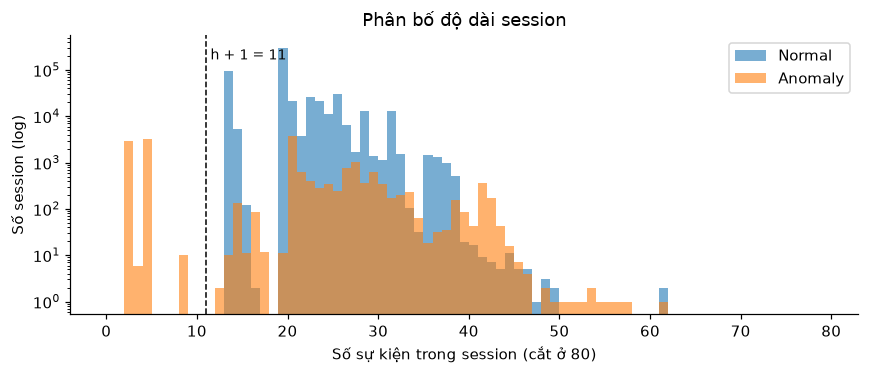

In [3]:
display(df.groupby(df.y.map({0: "Normal", 1: "Anomaly"}))["Len"].describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.arange(0, 80, 1)
ax.hist(df.loc[df.y == 0, "Len"], bins=bins, alpha=0.6, label="Normal", log=True)
ax.hist(df.loc[df.y == 1, "Len"], bins=bins, alpha=0.6, label="Anomaly", log=True)
ax.axvline(H + 1, color="k", ls="--", lw=1)
ax.text(H + 1.5, ax.get_ylim()[1] * 0.3, f"h + 1 = {H + 1}", fontsize=9)
ax.set_xlabel("Số sự kiện trong session (cắt ở 80)")
ax.set_ylabel("Số session (log)")
ax.set_title("Phân bố độ dài session")
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_session_length.png")
plt.show()

In [4]:
min_normal = df.loc[df.y == 0, "Len"].min()
short = df["Len"] <= H          # không tạo được cửa sổ nào (cần ít nhất h + 1 sự kiện)
below_min = df["Len"] < min_normal
print(f"Session Normal ngắn nhất: {min_normal} sự kiện")
print(f"Session có Len <= h = {H} (không tạo được cửa sổ nào): {short.sum():,}, trong đó Anomaly: {(short & (df.y == 1)).sum():,}")
print(f"Session có Len < {min_normal}: {below_min.sum():,}, trong đó Anomaly: {(below_min & (df.y == 1)).sum():,} "
      f"= {(below_min & (df.y == 1)).sum() / (df.y == 1).sum():.1%} tổng số Anomaly")

Session Normal ngắn nhất: 13 sự kiện
Session có Len <= h = 10 (không tạo được cửa sổ nào): 6,191, trong đó Anomaly: 6,191
Session có Len < 13: 6,193, trong đó Anomaly: 6,193 = 36.8% tổng số Anomaly


**Nhận xét.**
- Session Normal rất đều (trung vị 19, tối thiểu 13). Session Anomaly phân tán hơn nhiều: 1/4 số Anomaly có ≤ 4 sự kiện.
- **Mọi session có độ dài ≤ h đều là Anomaly** (khoảng 37% tổng số Anomaly). Các session này không tạo được cửa sổ nào cho
  LSTM, nên `detect.py` **bắt buộc** phải có quy tắc riêng cho chúng. Nếu bỏ qua session không có cửa sổ, recall mất ngay
  khoảng 37%. Nếu đánh dấu chúng là bất thường thì đúng 100% trên HDFS_v1. Có thể làm theo cách phổ biến là thêm sự kiện
  PAD vào đầu chuỗi để mọi sự kiện đều được dự đoán. Dù chọn cách nào cũng cần ghi rõ vào báo cáo, vì lựa chọn này ảnh
  hưởng trực tiếp tới F1.

## 3. Bất thường theo thời gian và mốc cắt chronological

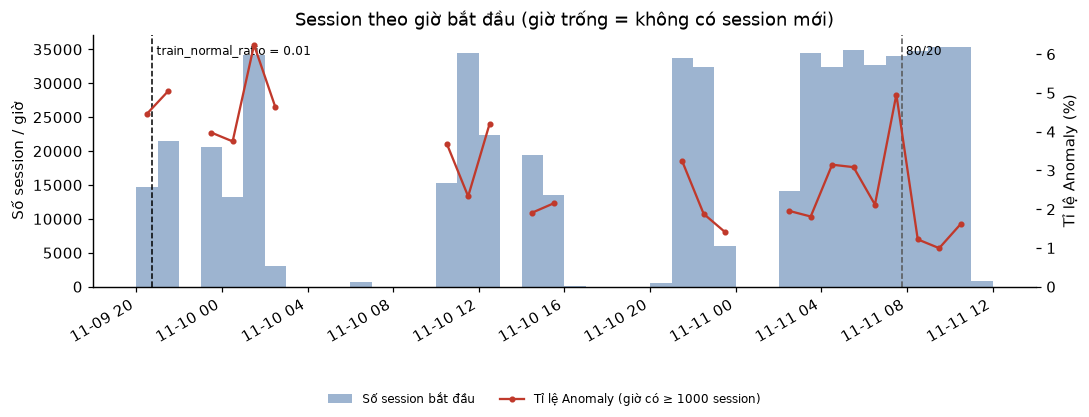

In [5]:
hourly = df.groupby(df.StartTime.dt.floor("h"))["y"].agg(sessions="size", anomalies="sum")
hourly["anomaly_rate"] = hourly.anomalies / hourly.sessions
hourly.loc[hourly.sessions < 1000, "anomaly_rate"] = np.nan   # giờ quá ít session → tỉ lệ không có ý nghĩa
full_index = pd.date_range(hourly.index.min(), hourly.index.max(), freq="h")
hourly = hourly.reindex(full_index)

normal_sorted = df.loc[df.y == 0].sort_values("StartTime")
ratio = cfg["split"]["train_normal_ratio"]
cutoffs = {
    f"train_normal_ratio = {ratio}": normal_sorted.StartTime.iloc[int(len(normal_sorted) * ratio) - 1],
    "80/20": normal_sorted.StartTime.iloc[int(len(normal_sorted) * 0.8) - 1],
}

fig, ax1 = plt.subplots(figsize=(10, 3.8))
ax1.bar(hourly.index, hourly.sessions.fillna(0), width=1 / 24, align="edge", color="#9db4d0", label="Số session bắt đầu")
ax1.set_ylabel("Số session / giờ")
ax2 = ax1.twinx()
ax2.plot(hourly.index + pd.Timedelta(minutes=30), hourly.anomaly_rate * 100, "o-", ms=3, color="#c0392b", label="Tỉ lệ Anomaly (giờ có ≥ 1000 session)")
ax2.set_ylim(bottom=0)
ax2.set_ylabel("Tỉ lệ Anomaly (%)")
for (name, t), c in zip(cutoffs.items(), ["k", "#555"]):
    ax1.axvline(t, color=c, ls="--", lw=1)
    ax1.text(t, ax1.get_ylim()[1] * 0.92, " " + name, fontsize=8)
ax1.set_title("Session theo giờ bắt đầu (giờ trống = không có session mới)")
fig.autofmt_xdate(); fig.tight_layout()
fig.subplots_adjust(bottom=0.3)
fig.legend(loc="lower center", ncol=2, fontsize=8, frameon=False)
fig.savefig(FIG_DIR / "eda_time.png")
plt.show()

In [6]:
rows = []
for name, cut in cutoffs.items():
    before = df.StartTime <= cut
    after = ~before
    rows.append({
        "Cách chia": name,
        "Mốc cắt": cut,
        "Normal trước mốc (train+val)": int((before & (df.y == 0)).sum()),
        "Anomaly trước mốc": int((before & (df.y == 1)).sum()),
        "Normal sau mốc (test)": int((after & (df.y == 0)).sum()),
        "Anomaly sau mốc (test)": int((after & (df.y == 1)).sum()),
        "Tỉ lệ Anomaly trong test": f"{df.loc[after, 'y'].mean():.2%}",
    })
pd.DataFrame(rows).set_index("Cách chia").T

Cách chia,train_normal_ratio = 0.01,80/20
Mốc cắt,2008-11-09 20:45:18,2008-11-11 07:45:31
Normal trước mốc (train+val),5584,446581
Anomaly trước mốc,204,15241
Normal sau mốc (test),552639,111642
Anomaly sau mốc (test),16634,1597
Tỉ lệ Anomaly trong test,2.92%,1.41%


**Nhận xét.**
- Session không bắt đầu đều theo thời gian: có nhiều khoảng trống dài (ví dụ sáng 10/11), tương ứng với các đợt chạy
  benchmark khác nhau. Tỉ lệ Anomaly cũng thay đổi theo giờ (từ khoảng 1% đến hơn 6%) và **giảm dần về cuối log**.
- Với `train_normal_ratio = 0.01`, toàn bộ dữ liệu train nằm trong **khoảng 10 phút đầu**. Mô hình chỉ thấy hành vi của
  một đợt chạy duy nhất, nên dễ báo nhầm (FP) ở các đợt sau. Đây là điểm cần theo dõi khi phân tích lỗi ở tuần 3.
- Với cách chia 80/20 theo thời gian, tập test chỉ còn khoảng 1,6 nghìn Anomaly (tỉ lệ 1,4%, chưa bằng một nửa mức 2,9% của
  toàn bộ dữ liệu). F1 trên tập test này **không so trực tiếp được** với F1 của bài báo DeepLog, và báo cáo cần nêu rõ.
- Câu hỏi còn treo trong `split_data.py` (session Anomaly bắt đầu trước mốc cắt thì bỏ hay đưa vào test): với cách chia 1%,
  chỉ có khoảng 200 session như vậy (khoảng 1% số Anomaly), nên chọn cách nào thì ảnh hưởng tới kết quả cũng nhỏ. Tuy vậy,
  đưa chúng vào test sẽ gần với cách bài báo làm hơn. Với 80/20 thì phần lớn Anomaly nằm trước mốc cắt, nên **không được bỏ**
  chúng nếu muốn tập test đủ lớn. Một cách là chỉ cắt theo thời gian cho Normal và đưa toàn bộ Anomaly vào test, nhưng như
  vậy lại là trộn dữ liệu "quá khứ" vào test. Cần chọn một cách và ghi lý do vào báo cáo.

## 4. Sự kiện nào phân biệt Normal và Anomaly?

In [7]:
event_ids = [f"E{i}" for i in range(1, 30)]
presence = pd.DataFrame({e: df["Seq"].map(lambda s, e=e: e in s) for e in event_ids})
ev = pd.DataFrame({
    "Template": [template_text[e] for e in event_ids],
    "% Normal có": presence[df.y == 0].mean().values * 100,
    "% Anomaly có": presence[df.y == 1].mean().values * 100,
    "Số Normal có": presence[df.y == 0].sum().values,
    "Số Anomaly có": presence[df.y == 1].sum().values,
}, index=event_ids)
ev.style.format({"% Normal có": "{:.2f}", "% Anomaly có": "{:.2f}"}).background_gradient(subset=["% Normal có", "% Anomaly có"], cmap="Blues")

,Template,% Normal có,% Anomaly có,Số Normal có,Số Anomaly có
E1,* Adding an already existing block *,0.00,0.03,0,5
E2,* Verification succeeded for *,14.45,12.21,80649,2056
E3,* Served block * to *,23.97,21.54,133807,3627
E4,* Got exception while serving * to *,22.59,18.87,126117,3178
E5,* Receiving block * src: * dest: *,100.00,100.00,558223,16838
E6,* Received block * src: * dest: * of size *,0.32,20.58,1778,3465
E7,* writeBlock * received exception *,0.00,19.62,0,3303
E8,* PacketResponder * for block * Interrupted *,0.00,0.27,0,46
E9,* Received block * of size * from *,100.00,63.14,558223,10631
E10,* PacketResponder * Exception *,0.00,0.40,0,67


Sự kiện CHƯA TỪNG xuất hiện trong session Normal: ['E1', 'E7', 'E8', 'E10', 'E12', 'E13', 'E14', 'E15', 'E17', 'E19', 'E24', 'E29']
Sự kiện có mặt trong 100% session Normal: ['E5', 'E9', 'E11', 'E22', 'E26']
Anomaly chứa ít nhất 1 sự kiện 'chỉ có ở Anomaly': 3,845
Anomaly THIẾU ít nhất 1 sự kiện 'luôn có ở Normal': 6,207


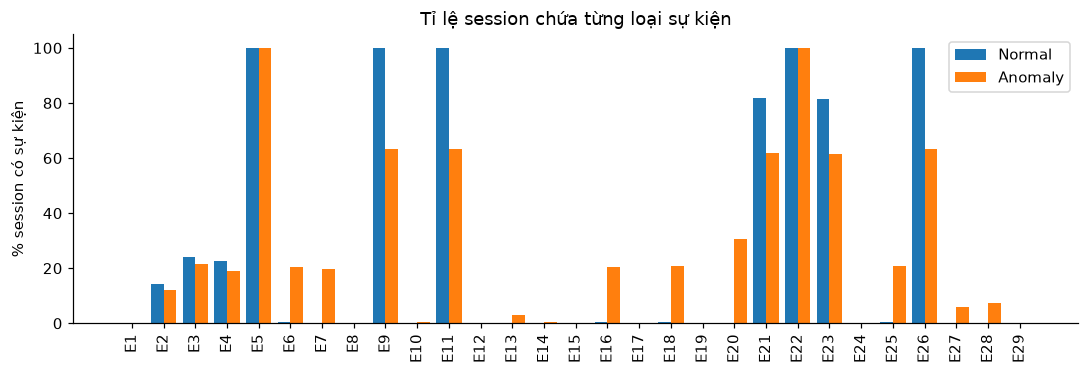

In [8]:
anomaly_only = ev.index[ev["Số Normal có"] == 0].tolist()
always_normal = ev.index[ev["% Normal có"] == 100].tolist()
print("Sự kiện CHƯA TỪNG xuất hiện trong session Normal:", anomaly_only)
print("Sự kiện có mặt trong 100% session Normal:", always_normal)

has_anomaly_only = presence[anomaly_only].any(axis=1)
missing_always = ~presence[always_normal].all(axis=1)
print(f"Anomaly chứa ít nhất 1 sự kiện 'chỉ có ở Anomaly': {(has_anomaly_only & (df.y == 1)).sum():,}")
print(f"Anomaly THIẾU ít nhất 1 sự kiện 'luôn có ở Normal': {(missing_always & (df.y == 1)).sum():,}")

fig, ax = plt.subplots(figsize=(10, 3.5))
x = np.arange(len(event_ids))
ax.bar(x - 0.2, ev["% Normal có"], 0.4, label="Normal")
ax.bar(x + 0.2, ev["% Anomaly có"], 0.4, label="Anomaly")
ax.set_xticks(x, event_ids, rotation=90)
ax.set_ylabel("% session có sự kiện")
ax.set_title("Tỉ lệ session chứa từng loại sự kiện")
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_event_presence.png")
plt.show()

**Nhận xét.**
- Có 12 loại sự kiện **chưa từng** xuất hiện trong session Normal (phần lớn là exception), và 5 loại sự kiện có mặt trong
  **mọi** session Normal (vòng đời chuẩn của 1 block: cấp phát → nhận → ghi xong → cập nhật blockMap).
- Nhiều bất thường thể hiện bằng **sự kiện bị thiếu** chứ không phải sự kiện lạ (phần lớn trùng với nhóm session quá ngắn
  ở Phần 2). Điều này khớp với nhận định ở Mục 2.2 của báo cáo tuần 1: bất thường không nhất thiết đi kèm dòng ERROR.
- Kết quả đáng chú ý cho DeepLog: một sự kiện chỉ có ở Anomaly sẽ có xác suất dự đoán gần 0, nên chắc chắn nằm ngoài top-g.
  Vì vậy loại bất thường này "dễ" với mọi giá trị g.

## 5. Hai baseline luật đơn giản (mốc dưới cùng)

In [9]:
# Mức độ (INFO/WARN) của từng template: quét các dòng WARN trong log gốc (~10 giây)
header_regex, _ = build_header_regex(cfg["parse"]["log_format"])
ref_match = build_reference_matcher(ref_templates)
warn_events = set()
with open(paths["raw_log"], encoding="utf-8", errors="replace") as f:
    for line in f:
        if " WARN " in line or " ERROR " in line or " FATAL " in line:
            m = header_regex.match(line.rstrip("\n"))
            if m and m["Level"] != "INFO":
                warn_events.add(ref_match(m["Content"]))
warn_events.discard(NO_MATCH)
print("Template có mức WARN:", sorted(warn_events, key=lambda e: int(e[1:])))

Template có mức WARN: ['E1', 'E4', 'E17', 'E20', 'E27', 'E29']


In [10]:
from sklearn.metrics import precision_recall_fscore_support

def score(name, pred):
    p, r, f, _ = precision_recall_fscore_support(df.y, pred, average="binary", zero_division=0)
    return {"Luật": name, "TP": int((pred & (df.y == 1)).sum()), "FP": int((pred & (df.y == 0)).sum()),
            "FN": int((~pred & (df.y == 1)).sum()), "Precision": p, "Recall": r, "F1": f}

warn_rule = presence[sorted(warn_events)].any(axis=1)
structural_rule = has_anomaly_only | missing_always | (df.Len < min_normal)
pd.DataFrame([
    score("Từ khoá: có dòng WARN", warn_rule),
    score("Cấu trúc: có sự kiện lạ / thiếu sự kiện bắt buộc / quá ngắn", structural_rule),
]).set_index("Luật").round(4)

,TP,FP,FN,Precision,Recall,F1
Luật,,,,,,
Từ khoá: có dòng WARN,8120,126120,8718,0.0605,0.4822,0.1075
Cấu trúc: có sự kiện lạ / thiếu sự kiện bắt buộc / quá ngắn,6795,0,10043,1.0000,0.4036,0.5750


**Nhận xét.**
- **Luật từ khoá WARN** cho precision rất thấp, vì `Got exception while serving block` là WARN nhưng xuất hiện trong khoảng
  23% session Normal. Đây là số liệu minh hoạ trực tiếp cho lập luận "chỉ tìm từ khoá là không đủ" ở Mục 2.2 báo cáo.
- **Luật cấu trúc** chỉ gồm 3 điều kiện viết tay. Lưu ý là luật này được "học" từ **toàn bộ** dữ liệu có nhãn, nên đây là
  một tham chiếu, không phải phương pháp hợp lệ. Luật bắt được khoảng 40% Anomaly mà **không có FP nào**: đây là phần "dễ"
  của HDFS_v1, nên DeepLog phải bắt được gần hết. **60% Anomaly còn lại chỉ gồm các sự kiện bình thường**, chỉ khác ở thứ tự
  hoặc số lần xuất hiện. Đây là phần cho biết DeepLog (mô hình chuỗi) có hơn phương pháp đếm hay không. Khi phân tích lỗi ở
  tuần 3, nên tách kết quả theo 2 nhóm này.
- Nên đưa luật từ khoá vào bảng so sánh cuối kỳ như một baseline dưới cùng, bên cạnh PCA và Isolation Forest.

## 6. Chuỗi trùng lặp

In [11]:
n_unique_normal = df.loc[df.y == 0, "Features"].nunique()
n_unique_anom = df.loc[df.y == 1, "Features"].nunique()
overlap = set(df.loc[df.y == 0, "Features"]) & set(df.loc[df.y == 1, "Features"])
print(f"Chuỗi Normal khác nhau: {n_unique_normal:,} / {(df.y == 0).sum():,}")
print(f"Chuỗi Anomaly khác nhau: {n_unique_anom:,} / {(df.y == 1).sum():,}")
print(f"Chuỗi xuất hiện ở cả 2 nhãn (nhiễu nhãn, không mô hình nào phân biệt được): {len(overlap)}"
      f" → {df.Features.isin(overlap).sum():,} session")

k = int(len(normal_sorted) * ratio)
train_keys = set(normal_sorted.Features.iloc[:k])
test_normal = normal_sorted.iloc[k:]
print(f"\nChia chronological {ratio}: train có {len(train_keys):,} chuỗi khác nhau")
print(f"  Normal test có chuỗi y hệt 1 chuỗi train: {test_normal.Features.isin(train_keys).mean():.1%}")

counts = df.loc[df.y == 0, "Features"].value_counts()
print(f"  10 chuỗi Normal phổ biến nhất chiếm {counts.iloc[:10].sum() / counts.sum():.1%} số session Normal")

Chuỗi Normal khác nhau: 14,259 / 558,223
Chuỗi Anomaly khác nhau: 4,124 / 16,838
Chuỗi xuất hiện ở cả 2 nhãn (nhiễu nhãn, không mô hình nào phân biệt được): 10 → 46 session

Chia chronological 0.01: train có 1,041 chuỗi khác nhau
  Normal test có chuỗi y hệt 1 chuỗi train: 2.9%
  10 chuỗi Normal phổ biến nhất chiếm 56.5% số session Normal


**Nhận xét.**
- 558 nghìn session Normal chỉ có khoảng 14 nghìn chuỗi khác nhau. Tuy vậy, với cách chia 1% theo thời gian, chỉ khoảng
  3% session Normal ở tập test có chuỗi y hệt một chuỗi đã thấy khi train, nên mô hình **không thể** đạt điểm cao chỉ bằng
  cách "nhớ" nguyên chuỗi. Điều này cũng giải thích vì sao DeepLog dùng cửa sổ trượt ngắn (h = 10) thay vì cả chuỗi.
- Có một số ít chuỗi mang cả hai nhãn (nhiễu nhãn, như nghiên cứu [8] đã nêu). Đây là giới hạn trên của mọi phương pháp.

## 7. Tóm tắt các phát hiện và đề xuất

1. **Parse.** `drain3.ini` mới cho chuỗi trùng khít Loghub (100%). Có thể dùng output Drain3 để train, không cần chuyển sang
   chuỗi đã tiền xử lý như phương án dự phòng ở Mục 8 báo cáo.
2. **Session ngắn.** Khoảng 37% Anomaly có ≤ h sự kiện và không có cửa sổ nào. `detect.py` cần có quy tắc riêng (đánh dấu
   bất thường, hoặc padding). Cần ghi rõ lựa chọn vì nó ảnh hưởng mạnh tới recall.
3. **Chia dữ liệu.** Với tỉ lệ 1%, dữ liệu train chỉ phủ khoảng 10 phút đầu. Tỉ lệ Anomaly giảm theo thời gian, nên tập test
   80/20 chỉ có 1,4% Anomaly. Báo cáo cần nêu rõ số Normal/Anomaly của mỗi tập.
4. **Baseline và phân tích lỗi.** Thêm luật từ khoá WARN (F1 khoảng 0,11) vào bảng so sánh. Khoảng 40% Anomaly bị luật cấu
   trúc bắt được mà không có FP. Recall của DeepLog nên được báo cáo riêng cho nhóm này và cho 60% Anomaly "chỉ khác thứ
   tự/số lần".
5. **Con số 4.855 của bài báo DeepLog** không tái tạo được bằng cách "lấy session trong 100k dòng đầu" (ra 7.627 session
   Normal, xem `outputs/results/parsing_validation.json`). Đề xuất dùng `train_normal_ratio` hoặc "4.855 session Normal
   đầu tiên theo thời gian" (bắt đầu trước dòng 62.060), và ghi rõ trong báo cáo.